# 04 – Combining Topics and Communities

**Goal:** answer the central question of SocialPulse: *do network communities talk about different topics, and who connects them?*

**Input:** `data/posts_with_topics.csv`, `data/user_communities.csv`
**Output:** `data/community_topic_share.csv`, `data/community_topic_summary.csv`, `data/user_summary.csv`, `heatmap.png`

**Analyses**
1. Join each post to its author's community
2. Topic mix of each community (heatmap)
3. Distinctive topics per community (lift)
4. Do communities and topics align? (NMI with a random baseline)
5. Do bridge users talk about more varied topics?
6. Topics over time

All charts use anonymous IDs, never real handles.

## 1. Load and join

Each post belongs to an author, and each author belongs to a network community. Joining on `author_did` gives every post both a topic (content) and a community (structure).

Only authors who appear in the follower graph have a community, so posts by other authors are dropped here. We also drop outlier posts that never received a topic (`-1`).

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy, mannwhitneyu
from sklearn.metrics import normalized_mutual_info_score, adjusted_mutual_info_score

posts = pd.read_csv("data/posts_with_topics.csv")
users = pd.read_csv("data/user_communities.csv")

df = posts.merge(
    users[["author_did", "community", "anon_id", "is_bridge", "degree", "external_ratio"]],
    on="author_did", how="inner")
df = df[df["topic_reduced"] != -1].copy()

print("posts before join:", len(posts))
print("posts with a community:", len(df))
print("users:", df["author_did"].nunique(), "| communities:", df["community"].nunique())

posts before join: 20452
posts with a community: 3517
users: 1822 | communities: 35


## 2. Settings and readable topic labels

- `MIN_USERS`: only communities with at least this many users are analysed, since tiny groups give noisy percentages.
- `TOP_TOPICS`, `TOP_COMMS`: how many topics and communities to show in charts.

Topic names like `3_openai_chatgpt_ai_model` are shortened to `T3: openai chatgpt ai`.

In [63]:
print("posts after join:", len(df))
print("users after join:", df["author_did"].nunique())
print("communities after join:", df["community"].nunique())
print("\nusers per community (top 15):")
print(comm_users.sort_values(ascending=False).head(15))

posts after join: 3517
users after join: 1822
communities after join: 35

users per community (top 15):
community
0     66
1     64
2     62
3     60
4     57
5     41
6     39
7     19
8     17
9      4
10     3
11     2
12     2
Name: author_did, dtype: int64


In [64]:
MIN_USERS = 10    # lower to 5 if you are testing on a small dataset
TOP_TOPICS = 20
TOP_COMMS = 10

def short_label(t, name):
    return f"T{t}: " + " ".join(str(name).split("_")[1:4])

names = df.groupby("topic_reduced")["topic_name"].first()
labels = {t: short_label(t, n) for t, n in names.items()}
df["topic_label"] = df["topic_reduced"].map(labels)

comm_users = df.groupby("community")["author_did"].nunique()
big = comm_users[comm_users >= MIN_USERS].sort_values(ascending=False).index[:TOP_COMMS]

print("communities analysed:", len(big))
print(comm_users.loc[big].to_dict())

communities analysed: 10
{0: 233, 1: 177, 2: 159, 3: 139, 4: 121, 5: 107, 6: 103, 7: 94, 8: 87, 9: 71}


## 3. Which topics does each community discuss?

For each community we compute the **share of its posts** in each topic (each row sums to 1). A bright cell means a community spends much of its attention on that topic.

This heatmap is the main figure of the project. If communities have different bright cells, structure and content are linked.

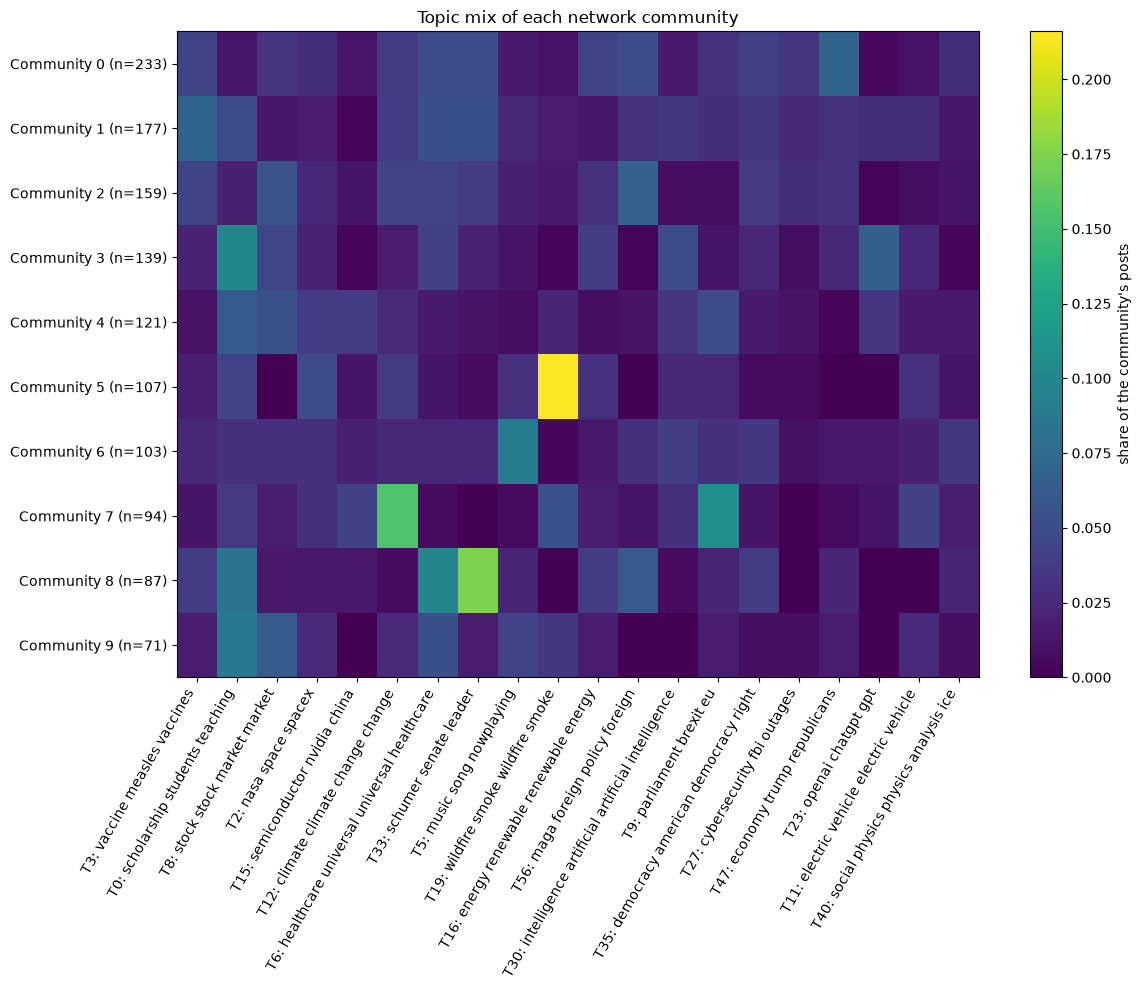

In [65]:
ct = pd.crosstab(df["community"], df["topic_reduced"]).loc[big]
share = ct.div(ct.sum(axis=1), axis=0)

top_topics = df["topic_reduced"].value_counts().head(TOP_TOPICS).index
plot_data = share[top_topics]

fig, ax = plt.subplots(figsize=(12, 0.6 * len(plot_data) + 4))
im = ax.imshow(plot_data.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(top_topics)))
ax.set_xticklabels([labels[t] for t in top_topics], rotation=60, ha="right")
ax.set_yticks(range(len(plot_data)))
ax.set_yticklabels([f"Community {c} (n={comm_users[c]})" for c in plot_data.index])
plt.colorbar(im, label="share of the community's posts")
ax.set_title("Topic mix of each network community")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. What makes each community different?

The most common topic in a community may also be common everywhere. **Lift** fixes this by dividing the community's share of a topic by the topic's share in the whole dataset:

- Lift 1: the community discusses the topic as much as everyone does
- Lift 3: three times more than average, which makes it distinctive

We only count topics with at least 5 posts in the community, so tiny counts don't produce huge lifts.

In [66]:
overall = df["topic_reduced"].value_counts(normalize=True)
lift = share.div(overall, axis=1)

rows = []
for c in share.index:
    ok = lift.loc[c][ct.loc[c] >= 5].sort_values(ascending=False).head(3)
    rows.append({
        "community": c,
        "users": int(comm_users[c]),
        "posts": int(ct.loc[c].sum()),
        "dominant_topics": "; ".join(labels[t] for t in share.loc[c].nlargest(3).index),
        "distinctive_topics": "; ".join(labels[t] for t in ok.index),
    })

summary = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
summary

,community,users,posts,dominant_topics,distinctive_topics
0,0,233,387,T47: economy trump republicans; T6: healthcare universal universal healthcare; T33: schumer senate leader,T47: economy trump republicans; T44: ukraine putin russia; T57: foxx virginia virginia foxx
1,1,177,286,T3: vaccine measles vaccines; T6: healthcare universal universal healthcare; T33: schumer senate leader,T46: seats 258 house; T28: biology trans sex; T42: economy rich wealth
2,2,159,250,T56: maga foreign policy foreign; T8: stock stock market market; T3: vaccine measles vaccines,T44: ukraine putin russia; T56: maga foreign policy foreign; T57: foxx virginia virginia foxx
3,3,139,238,T0: scholarship students teaching; T34: physics quantum gravity; T23: openai chatgpt gpt,T34: physics quantum gravity; T29: biology evolutionary philosopher; T43: ai students use
4,4,121,262,T24: open source source open; T0: scholarship students teaching; T8: stock stock market market,T24: open source source open; T28: biology trans sex; T14: anime episode watch
5,5,107,162,T19: wildfire smoke wildfire smoke; T13: league premier premier league; T2: nasa space spacex,T19: wildfire smoke wildfire smoke; T68: palisades deadly los; T13: league premier premier league
6,6,103,199,T13: league premier premier league; T5: music song nowplaying; T30: intelligence artificial artificial intelligence,T13: league premier premier league; T5: music song nowplaying; T4: mental mental health health
7,7,94,166,T12: climate climate change change; T9: parliament brexit eu; T21: sustainability environmental sustainable,T12: climate climate change change; T9: parliament brexit eu; T21: sustainability environmental sustainable
8,8,87,132,T33: schumer senate leader; T6: healthcare universal universal healthcare; T0: scholarship students teaching,T33: schumer senate leader; T57: foxx virginia virginia foxx; T6: healthcare universal universal healthcare
9,9,71,114,T22: ruin letter movie; T0: scholarship students teaching; T8: stock stock market market,T22: ruin letter movie; T46: seats 258 house; T0: scholarship students teaching


## 5. Headline result: do communities and topics align?

We give each user a **dominant topic** (the topic they post about most) and compare it with their community using:

- **NMI** (normalized mutual information): 0 means the two labelings are unrelated, 1 means they match perfectly.
- **AMI** (adjusted mutual information): the same idea, corrected for the chance agreement that appears when there are many groups.

NMI alone can look large just because there are many communities and topics. So we also compute it **after randomly shuffling community labels** 200 times. Real alignment must clearly beat that random baseline.

Only users with at least `MIN_POSTS_USER` posts are used, because a dominant topic from one post is unreliable.

users used: 264
NMI: 0.436
AMI: 0.063
random baseline NMI: mean 0.398 | 95th percentile 0.411
permutation p-value: 0.005


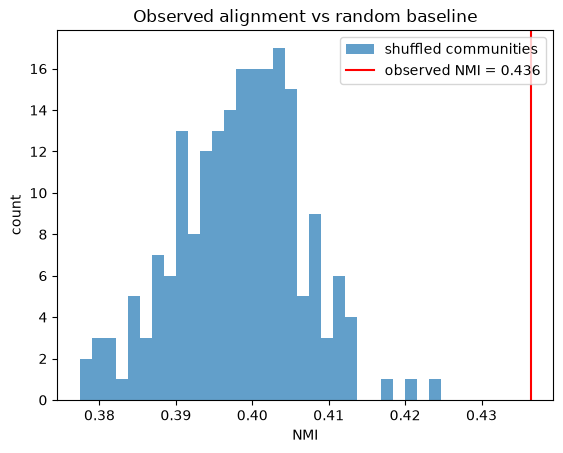

In [67]:
MIN_POSTS_USER = 3

user_topic = df.groupby("author_did")["topic_reduced"].agg(lambda s: s.mode().iloc[0])
n_posts = df.groupby("author_did").size()

u = users.set_index("author_did").join(user_topic.rename("dom_topic"), how="inner")
u["n_posts"] = n_posts.reindex(u.index)
u = u[u["n_posts"] >= MIN_POSTS_USER]

nmi = normalized_mutual_info_score(u["community"], u["dom_topic"])
ami = adjusted_mutual_info_score(u["community"], u["dom_topic"])

rng = np.random.default_rng(42)
null = np.array([
    normalized_mutual_info_score(rng.permutation(u["community"].values), u["dom_topic"])
    for _ in range(200)])
p_value = (np.sum(null >= nmi) + 1) / (len(null) + 1)

print("users used:", len(u))
print("NMI:", round(nmi, 3))
print("AMI:", round(ami, 3))
print("random baseline NMI: mean", round(null.mean(), 3), "| 95th percentile", round(np.percentile(null, 95), 3))
print("permutation p-value:", round(p_value, 4))

plt.hist(null, bins=30, alpha=0.7, label="shuffled communities")
plt.axvline(nmi, color="red", label=f"observed NMI = {nmi:.3f}")
plt.xlabel("NMI"); plt.ylabel("count"); plt.legend()
plt.title("Observed alignment vs random baseline")
plt.show()

## 6. Do bridge users talk about more varied topics?

A bridge user has many links to other communities. If bridges really connect groups, we might expect their posts to cover **more different topics**. We measure this with **topic entropy** per user: 0 means all posts are on one topic, and higher means a wider spread.

We compare bridge and non-bridge users with a Mann-Whitney test, which does not assume a normal distribution.

In [68]:
def topic_entropy(s):
    return entropy(s.value_counts(normalize=True), base=2)

ent = df.groupby("author_did")["topic_reduced"].apply(topic_entropy)
u["entropy"] = ent.reindex(u.index)

print(u.groupby("is_bridge")["entropy"].agg(["count", "mean", "median"]).round(3))

a = u.loc[u["is_bridge"], "entropy"].dropna()
b = u.loc[~u["is_bridge"], "entropy"].dropna()
if len(a) >= 5 and len(b) >= 5:
    stat, p = mannwhitneyu(a, b, alternative="two-sided")
    print("Mann-Whitney p-value:", round(p, 4))
else:
    print("Too few bridge users with enough posts for a test; collect more data.")

           count   mean  median
is_bridge                      
False        256  1.301   1.500
True           8  1.799   1.585
Mann-Whitney p-value: 0.1188


In [69]:
bt = pd.crosstab(df["is_bridge"], df["topic_reduced"], normalize="index").T
bt = bt.rename(columns={False: "non_bridge", True: "bridge"})
if {"bridge", "non_bridge"} <= set(bt.columns):
    bt["diff"] = bt["bridge"] - bt["non_bridge"]
    bt.index = [labels[t] for t in bt.index]
    print("Over-represented among bridge users:")
    print(bt["diff"].sort_values(ascending=False).head(5).round(3))
    print("\nUnder-represented:")
    print(bt["diff"].sort_values().head(5).round(3))

Over-represented among bridge users:
T47: economy trump republicans        0.074
T34: physics quantum gravity          0.054
T57: foxx virginia virginia foxx      0.044
T3: vaccine measles vaccines          0.040
T12: climate climate change change    0.034
Name: diff, dtype: float64

Under-represented:
T8: stock stock market market     -0.040
T15: semiconductor nvidia china   -0.035
T5: music song nowplaying         -0.030
T2: nasa space spacex             -0.022
T10: cricket australia matches    -0.020
Name: diff, dtype: float64


## 7. Topics over time

We count posts per day (or per week, if the data covers more than 3 weeks) for the 5 biggest topics.

**Caution:** Bluesky search returns the most recent matching posts, so our data may cover only a short window. If so, treat this chart as descriptive and don't claim long-term trends.

data covers 8 days; grouping by D


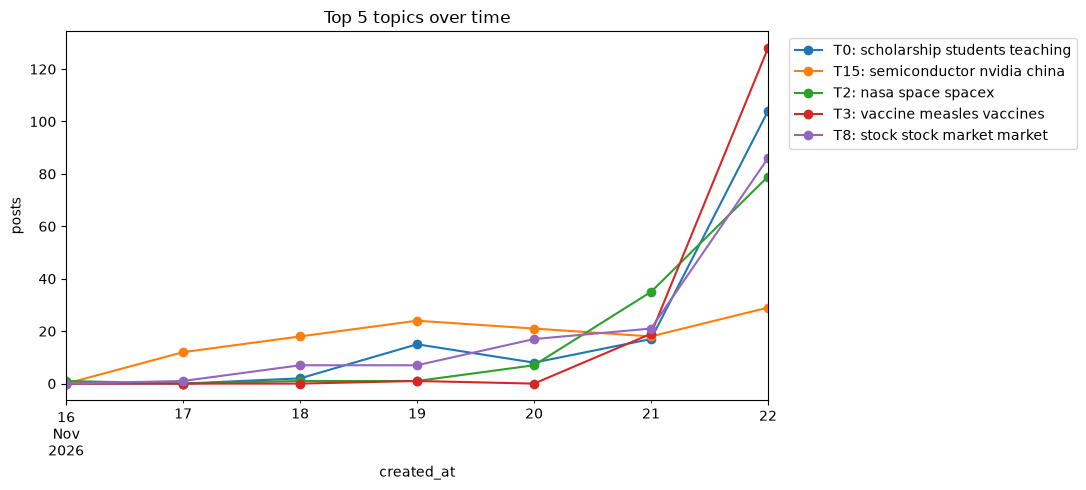

In [71]:
df["created_at"] = pd.to_datetime(df["created_at"], utc=True, format="ISO8601", errors="coerce")
df = df.dropna(subset=["created_at"])
df["topic_label"] = df["topic_reduced"].map(labels)

span_days = (df["created_at"].max() - df["created_at"].min()).days
freq = "D" if span_days < 21 else "W"
print("data covers", span_days, "days; grouping by", freq)

top5 = df["topic_reduced"].value_counts().head(5).index
trend = (df[df["topic_reduced"].isin(top5)]
         .groupby([pd.Grouper(key="created_at", freq=freq), "topic_label"])
         .size().unstack(fill_value=0))

trend.plot(figsize=(11, 5), marker="o")
plt.ylabel("posts"); plt.title("Top 5 topics over time")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 8. Save results

Only aggregated tables and anonymous IDs are saved here, which is safe to describe in a report.

In [72]:
share.to_csv("data/community_topic_share.csv")
lift.to_csv("data/community_topic_lift.csv")
summary.to_csv("data/community_topic_summary.csv", index=False)

(u.reset_index(drop=True)
  [["anon_id", "community", "dom_topic", "n_posts", "entropy", "is_bridge"]]
  .to_csv("data/user_summary.csv", index=False))

print("saved results")

saved results


## Summary

- Combined **N** posts from **U** users in **K** analysed communities.
- The heatmap shows (describe in your own words which communities focus on which topics).
- **Alignment:** NMI = X, AMI = Y, versus a random baseline of Z (p = P). (State plainly whether alignment is strong, weak or absent.)
- **Bridge users:** they [do / do not] post about a wider range of topics (entropy A vs B). Topics most associated with bridges: (list).
- **Limitations**
  - Keyword search samples only posts that contain our keywords.
  - Following does not equal agreeing with someone.
  - Dominant topic is a simplification, because users post about several topics.
  - Results depend on BERTopic's `MIN_TOPIC_SIZE` and Louvain's `resolution`.
  - Short time window, so no trend claims.